---
title: Week 6 Challenge 1
subtitle: DS 2023 | Communicating with Data
---

## Overview

In today's challenge, you will apply what you have learned about Seaborn's Axes-level functions.

Use the notebook **Introducing Seaborn** as your guide.

Work in groups to perform the tasks.

When finished, submit a URL to this notebook in your GitHub repo to today's participation assignment.

## The data set

Today's dataset is a collection of $515$ menu items from eight major US fast food chains, compiled from their nutritional information pages.

Each row is one menu item.

**Data dictionary**

| Variable | Data Type | Domain / Range | Description |
|---|---|---|---|
| restaurant | Categorical | Arbys, Burger King, Chick Fil-A, Dairy Queen, Mcdonalds, Sonic, Subway, Taco Bell | Fast food chain. |
| item | String | — | Name of the menu item. |
| calories | Integer | 20 – 2430 | Total calories. |
| total_fat | Integer | 0 – 141 | Total fat in grams. |
| sat_fat | Continuous | 0 – 43.2 | Saturated fat in grams. |
| sodium | Integer | 15 – 6080 | Sodium in milligrams (daily limit ≈ 2300 mg). |
| total_carb | Integer | 0 – 153 | Total carbohydrates in grams. |
| protein | Continuous | 1 – 186 | Protein in grams. |
| sugar | Integer | 0 – 87 | Sugar in grams. |

We will work mostly with `restaurant`, `calories`, `total_fat`, `sodium`, and `protein`.

## Set Up

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
data_url = "https://virginia.box.com/shared/static/w5bckp31x5u0u0q70166vemqzagr8w66.csv"
fastfood = pd.read_csv(data_url, index_col=0)
fastfood.index.name = 'item_id'
fastfood.info()
fastfood.head()

<class 'pandas.DataFrame'>
RangeIndex: 515 entries, 1 to 515
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   restaurant   515 non-null    str    
 1   item         515 non-null    str    
 2   calories     515 non-null    int64  
 3   cal_fat      515 non-null    int64  
 4   total_fat    515 non-null    int64  
 5   sat_fat      515 non-null    float64
 6   trans_fat    515 non-null    float64
 7   cholesterol  515 non-null    int64  
 8   sodium       515 non-null    int64  
 9   total_carb   515 non-null    int64  
 10  fiber        503 non-null    float64
 11  sugar        515 non-null    int64  
 12  protein      514 non-null    float64
 13  vit_a        301 non-null    float64
 14  vit_c        305 non-null    float64
 15  calcium      305 non-null    float64
 16  salad        515 non-null    str    
dtypes: float64(7), int64(7), str(3)
memory usage: 88.3 KB


,restaurant,item,calories,cal_fat,total_fat,sat_fat,trans_fat,cholesterol,sodium,total_carb,fiber,sugar,protein,vit_a,vit_c,calcium,salad
item_id,,,,,,,,,,,,,,,,,
1,Mcdonalds,Artisan Grilled Chicken Sandwich,380,60,7,2.0,0.0,95,1110,44,3.0,11,37.0,4.0,20.0,20.0,Other
2,Mcdonalds,Single Bacon Smokehouse Burger,840,410,45,17.0,1.5,130,1580,62,2.0,18,46.0,6.0,20.0,20.0,Other
3,Mcdonalds,Double Bacon Smokehouse Burger,1130,600,67,27.0,3.0,220,1920,63,3.0,18,70.0,10.0,20.0,50.0,Other
4,Mcdonalds,Grilled Bacon Smokehouse Chicken Sandwich,750,280,31,10.0,0.5,155,1940,62,2.0,18,55.0,6.0,25.0,20.0,Other
5,Mcdonalds,Crispy Bacon Smokehouse Chicken Sandwich,920,410,45,12.0,0.5,120,1980,81,4.0,18,46.0,6.0,20.0,20.0,Other


## Tasks

### Task 1

Use `sns.countplot()` to show the number of menu items per `restaurant`, drawn two ways:

- Left panel: bars in **alphabetical order** — use `order=sorted(fastfood['restaurant'].unique())`.
- Right panel: bars sorted from **most to fewest** — use `order=fastfood['restaurant'].value_counts().index`.

Which chain offers the most items? Which offers the fewest?
Why might a large menu not be an advantage?

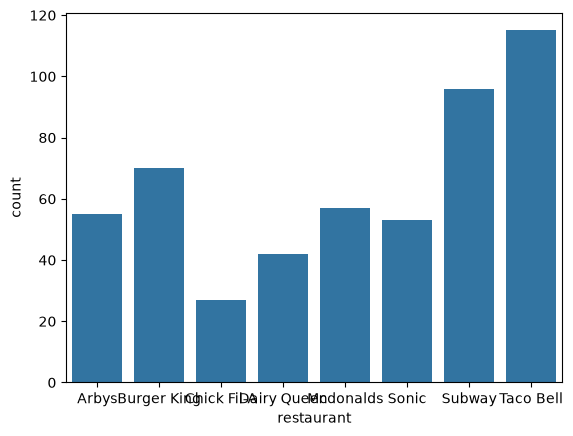

In [26]:
sns.countplot(fastfood, x = 'restaurant',order=sorted(fastfood['restaurant'].unique()))
plt.show()

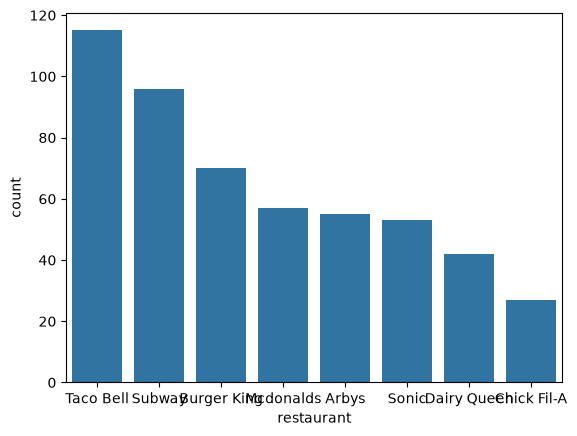

In [29]:
sns.countplot(fastfood, x = 'restaurant', order=fastfood['restaurant'].value_counts().index)
plt.show()

Taco Bell offers the most items, while Chick Fil-A offers the fewest.
A large menu might not be an advantage because customers overall may favor specific items that the chain offers.

### Task 2

Use `sns.barplot()` to show the **mean calorie count** by `restaurant`.

Use `order=fastfood.groupby('restaurant').calories.mean().sort_values(ascending=False).index` to sort bars from highest to lowest.

Draw it twice — once with the default error bars and once with `errorbar=None`.

Which chain has the highest mean calories? Which has the lowest?
What do the error bars tell you about menu diversity?

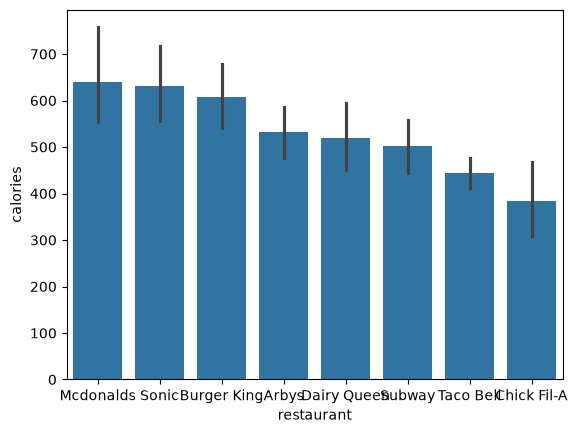

In [32]:
sns.barplot(fastfood, x='restaurant', y='calories', order=fastfood.groupby('restaurant').calories.mean().sort_values(ascending=False).index)
plt.show()

### Task 3

Use `sns.scatterplot()` to plot `calories` on the x-axis and `sodium` on the y-axis.

Set `hue='restaurant'` and `alpha=0.5`.

Describe the overall relationship between calories and sodium.
Does any restaurant stand out as having unusually high sodium for a given calorie level?

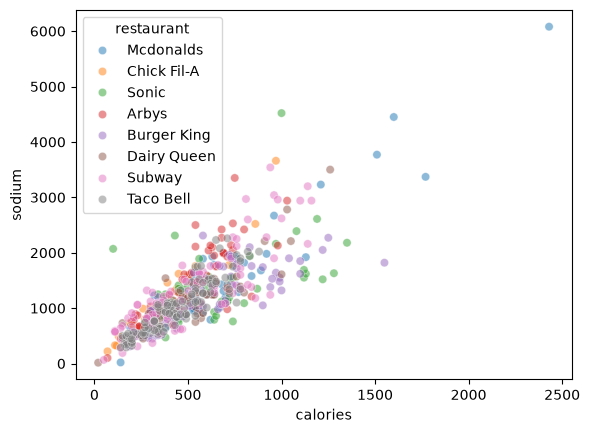

In [33]:
sns.scatterplot(fastfood, x='calories', y='sodium', hue='restaurant', alpha=0.5)
plt.show()

There is a direct, positive relationship between calories and sodium. Mcdonalds has an unusually high sodium overall, but is is proportional to the number of calories.

### Task 4

Use `sns.regplot()` to draw an overall regression line for `calories` vs `total_fat` (gray, no scatter points).

Then add per-restaurant regression lines on the same axes using a `groupby` loop.

Are the per-restaurant slopes similar or different? What does this tell you about the relationship between fat and calories across chains?

NameError: name 'ax' is not defined

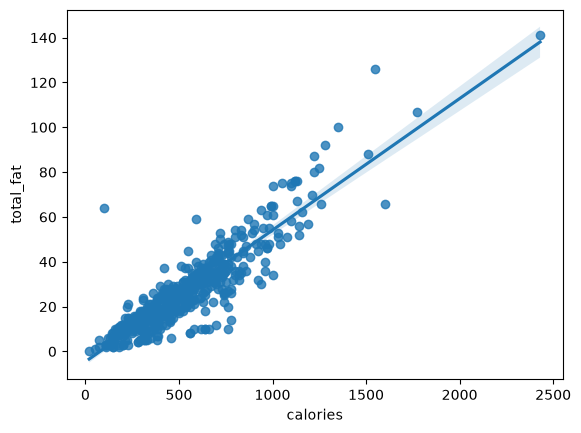

In [36]:
sns.regplot(fastfood, x='calories', y='total_fat')

for calories, subset in fastfood.groupby('calories'):
    sns.regplot(subset, x='calories', y='total_fat', ax=ax, label=calories)

    

ax.set_xlabel("calories")
ax.set_ylabel("Total Fat")
ax.legend(title="Calories vs Total Fat")

plt.show()

### Task 5

Create a figure showing a combined histogram and kde plot for `calories` for each restaurant using Seaborn's functions for these.

It should have one column and as many rows as there are restaurants.

Which chains have the widest spread of calorie counts? 

### Task 6

The dataset's `salad` column is all "Other" — not useful. But the item names themselves tell us which items are salads.

First, add a column that flags salad items:

```python
fastfood['is_salad'] = (
    fastfood['item'].str.lower().str.contains('salad')
    .map({True: 'Salad', False: 'Other'})
)
```

Then use `sns.boxplot()` to show `sodium` by `restaurant`, sorted from highest to lowest median sodium, with `hue='is_salad'`.

Are salad items meaningfully lower in sodium than the rest of the menu?